<a href="https://colab.research.google.com/github/anabellalongo/analisis-de-WLC/blob/main/prueba_medir_iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Objetivo: automatizar la medición del iris a partir de una foto.
Hoy me fijo lo de detectar y medir un círculo en píxeles. La calibración la resuelvo luego.

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import seaborn as sns
# import seaborn.objects as so
import os
# import re
# import math

from PIL import Image

#Detección y medición, primer prueba

##importe y recorte

Tamaño original: (4080, 3072)
Tamaño recortado: (400, 300)


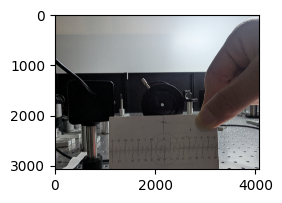

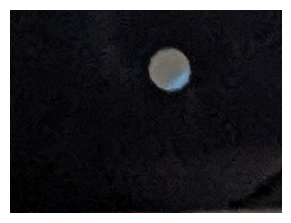

In [ ]:
ruta_imagen = '/content/drive/MyDrive/Laboratorio 6/Mediciones/PXL_20260910_174253531.jpg'

imagen = Image.open(ruta_imagen)

print("Tamaño original:", imagen.size)

marco=(1900, 1700, 2300, 2000)#1000+a, 1000+a)
recorte = imagen.crop(marco)
#recorta para esos valores de pixeles de (izq, arr, der, aba)

print("Tamaño recortado:", recorte.size)

plt.figure(figsize=(4, 2))
plt.imshow(imagen)
plt.show()

plt.figure(figsize=(3.5, 3.5))
plt.imshow(recorte)
plt.axis('off')
plt.show()

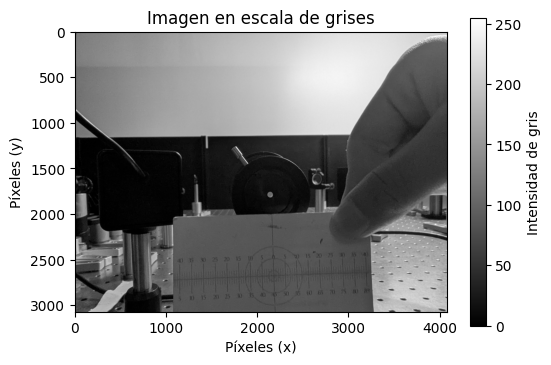

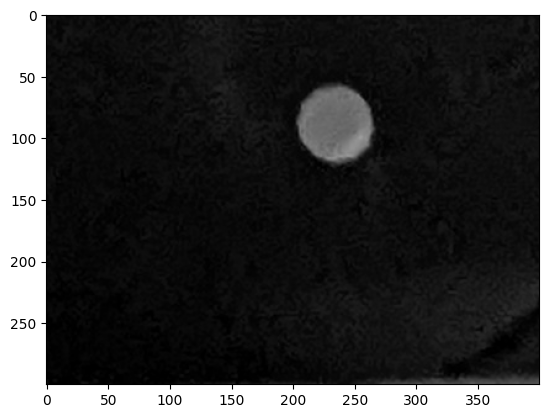

In [ ]:
import cv2

# Convertir la imagen PIL a un array de NumPy
img = np.array(imagen)
img_rec = np.array(recorte)

# Si la imagen tiene 3 canales de color, convertirla a escala de grises
if img.ndim == 3:
    gris = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
else:
    gris = img.copy()

# Convertir a escala de grises si tiene canales de color
if img_rec.ndim == 3:
    gris_recorte = cv2.cvtColor(
        img_rec, cv2.COLOR_RGB2GRAY
    )
else:
    gris_recorte = img_rec.copy()

# Mostrar la imagen en escala de grises
plt.figure(figsize=(6, 4))

plt.imshow(gris, cmap="gray", vmin=0, vmax=255)
plt.colorbar(label="Intensidad de gris")# (0 = negro, 255 = blanco)")

plt.title("Imagen en escala de grises")
plt.xlabel("Píxeles (x)")
plt.ylabel("Píxeles (y)")
plt.show()

plt.imshow(gris_recorte, cmap="gray", vmin=0, vmax=255)


##máscara y contornos

Recorte la imagen para sacar los puntos blancos de intensidad similar a la del circulo que me interesa y plotee la escala de grises porque lo siguiente que hace es tomar los puntos "blancos" a partir del umbral de intensidad y después busca su contorno

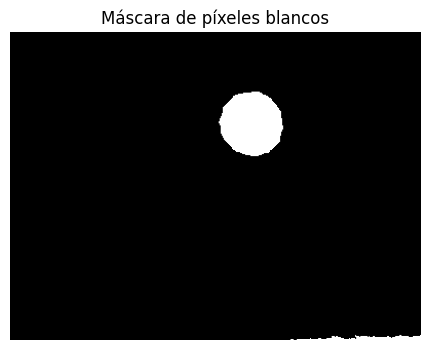

In [ ]:
#uso img o img_rec dependiendo de a partir de cual quiero hacer la mascara. El resto del codigo va a trabajar sobre la mascara
# Aplicar el umbral de 60
umbral = 60
mascara = (gris_recorte > umbral).astype(np.uint8) * 255

plt.figure(figsize=(6, 4))
plt.imshow(mascara, cmap="gray")
plt.title("Máscara de píxeles blancos")
plt.axis("off")
plt.show()

Cantidad de contornos encontrados: 3


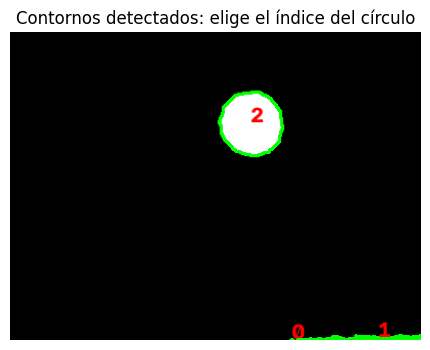

In [ ]:
# Buscar los contornos en la máscara
contornos, _ = cv2.findContours(
    mascara,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print(f"Cantidad de contornos encontrados: {len(contornos)}")

# Crear una imagen en color para visualizarlos
visualizacion = cv2.cvtColor(mascara, cv2.COLOR_GRAY2RGB)

for i, contorno in enumerate(contornos):
    # Dibujar el contorno en verde
    cv2.drawContours(
        visualizacion, [contorno], -1, (0, 255, 0), 2
    )

    # Calcular el centro aproximado de cada contorno usando 'contorno'
    M = cv2.moments(contorno)

    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
    else:
        x, y, w, h = cv2.boundingRect(contorno)
        cx = x + w // 2
        cy = y + h // 2

    # Escribir el índice del contorno
    cv2.putText(
        visualizacion,
        str(i),
        (cx, cy),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(6, 4))
plt.imshow(visualizacion)
plt.title("Contornos detectados: elige el índice del círculo")
plt.axis("off")
plt.show()

Contorno elegido: 2
Centro X: 234.31 píxeles
Centro Y: 89.31 píxeles
Radio: 32.33 píxeles
Diámetro: 64.66 píxeles


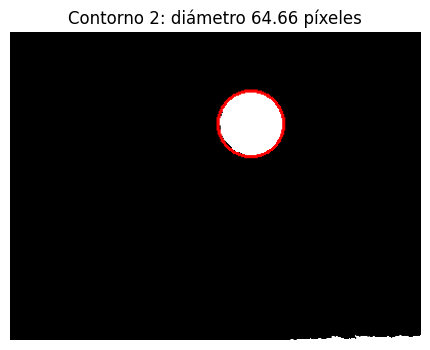

In [ ]:
# Elegir el índice del contorno que quieres medir
indice = 2

if 0 <= indice < len(contornos):
    contorno = contornos[indice]

    # Calcular el círculo que contiene ese contorno
    (cx, cy), radio = cv2.minEnclosingCircle(contorno)

    diametro = 2 * radio

    print(f"Contorno elegido: {indice}")
    print(f"Centro X: {cx:.2f} píxeles")
    print(f"Centro Y: {cy:.2f} píxeles")
    print(f"Radio: {radio:.2f} píxeles")
    print(f"Diámetro: {diametro:.2f} píxeles")

    # Dibujar el círculo calculado
    resultado = cv2.cvtColor(mascara, cv2.COLOR_GRAY2RGB)

    cv2.circle(
        resultado,
        (round(cx), round(cy)),
        round(radio),
        (255, 0, 0),
        2
    )

    plt.figure(figsize=(6, 4))
    plt.imshow(resultado)
    plt.title(f"Contorno {indice}: diámetro {diametro:.2f} píxeles")
    plt.axis("off")
    plt.show()

else:
    print("El índice seleccionado no existe.")


##codigo que no usé

In [ ]:
#area de n contorno generico, sin ser un circulo:


# Elegir el contorno que quieres medir
indice = 0
contorno = contornos[indice]

# Calcular el área encerrada
area = cv2.contourArea(contorno)

print(f"Área del contorno: {area:.2f} píxeles²")


# Crear una imagen RGB a partir de la máscara
resultado = cv2.cvtColor(mascara, cv2.COLOR_GRAY2RGB)

# Dibujar el contorno seleccionado en verde
cv2.drawContours(
    resultado,
    [contorno],
    -1,
    (0, 255, 0),
    2
)

# Obtener un punto interior para ubicar el texto
M = cv2.moments(contorno)

if M["m00"] != 0:
    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])
else:
    x, y, w, h = cv2.boundingRect(contorno)
    cx = x + w // 2
    cy = y + h // 2

# Mostrar el área
cv2.putText(
    resultado,
    f"Area: {area:.1f} px2",
    (cx, cy),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.6,
    (255, 0, 0),
    2
)

plt.figure(figsize=(7, 5))
plt.imshow(resultado)
plt.title("Área del contorno seleccionado")
plt.axis("off")
plt.show()

In [ ]:


if len(contornos) == 0:
    print("No se encontró ningún círculo.")
else:
    # Seleccionar el contorno de mayor área
    contorno = max(contornos, key=cv2.contourArea)

    # Calcular el centro y el radio del círculo envolvente
    (cx, cy), radio = cv2.minEnclosingCircle(contorno)

    # Calcular el diámetro
    diametro = 2 * radio

    # Obtener también ancho y alto del contorno
    x, y, ancho, alto = cv2.boundingRect(contorno)

    print(f"Centro X: {cx:.2f} píxeles")
    print(f"Centro Y: {cy:.2f} píxeles")
    print(f"Radio: {radio:.2f} píxeles")
    print(f"Diámetro estimado: {diametro:.2f} píxeles")
    print(f"Ancho del contorno: {ancho} píxeles")
    print(f"Alto del contorno: {alto} píxeles")
    print(f"Área del contorno: {cv2.contourArea(contorno):.0f} píxeles²")


Centro X: 434.31 píxeles
Centro Y: 289.31 píxeles
Radio: 32.33 píxeles
Diámetro estimado: 64.66 píxeles
Ancho del contorno: 63 píxeles
Alto del contorno: 63 píxeles
Área del contorno: 2942 píxeles²


#generalizo para varios umbrales, segunda prueba

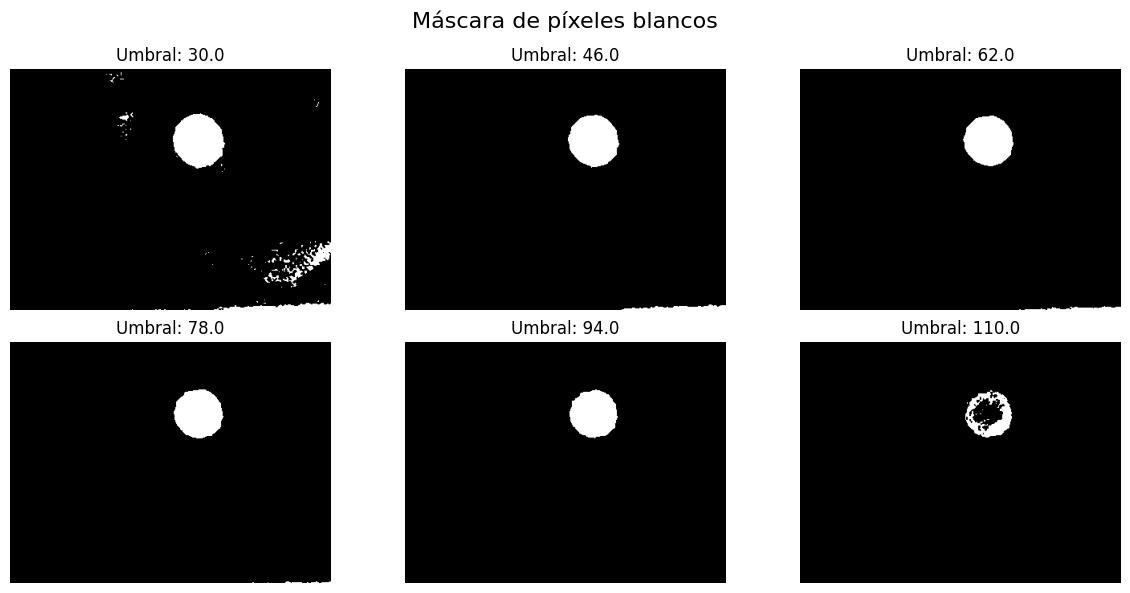

In [ ]:
#uso img o img_rec dependiendo de a partir de cual quiero hacer la mascara. El resto del codigo va a trabajar sobre la mascara
# Aplicar el umbral de 60
mascaras=[]
umbral = np.linspace(30, 110, 6)

# Crear una única figura con 2 filas y 3 columnas
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
fig.suptitle("Máscara de píxeles blancos", fontsize=16) # Corregido: se usa suptitle para la figura completa
axes = axes.flatten()  # Aplanar la matriz de subplots para iterar fácilmente

for i in range(6):
    mascara = (gris_recorte > umbral[i]).astype(np.uint8) * 255
    mascaras.append(mascara)

    # Mostrar cada máscara en su subplot correspondiente
    axes[i].imshow(mascara, cmap="gray")
    axes[i].set_title(f"Umbral: {umbral[i]:.1f}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

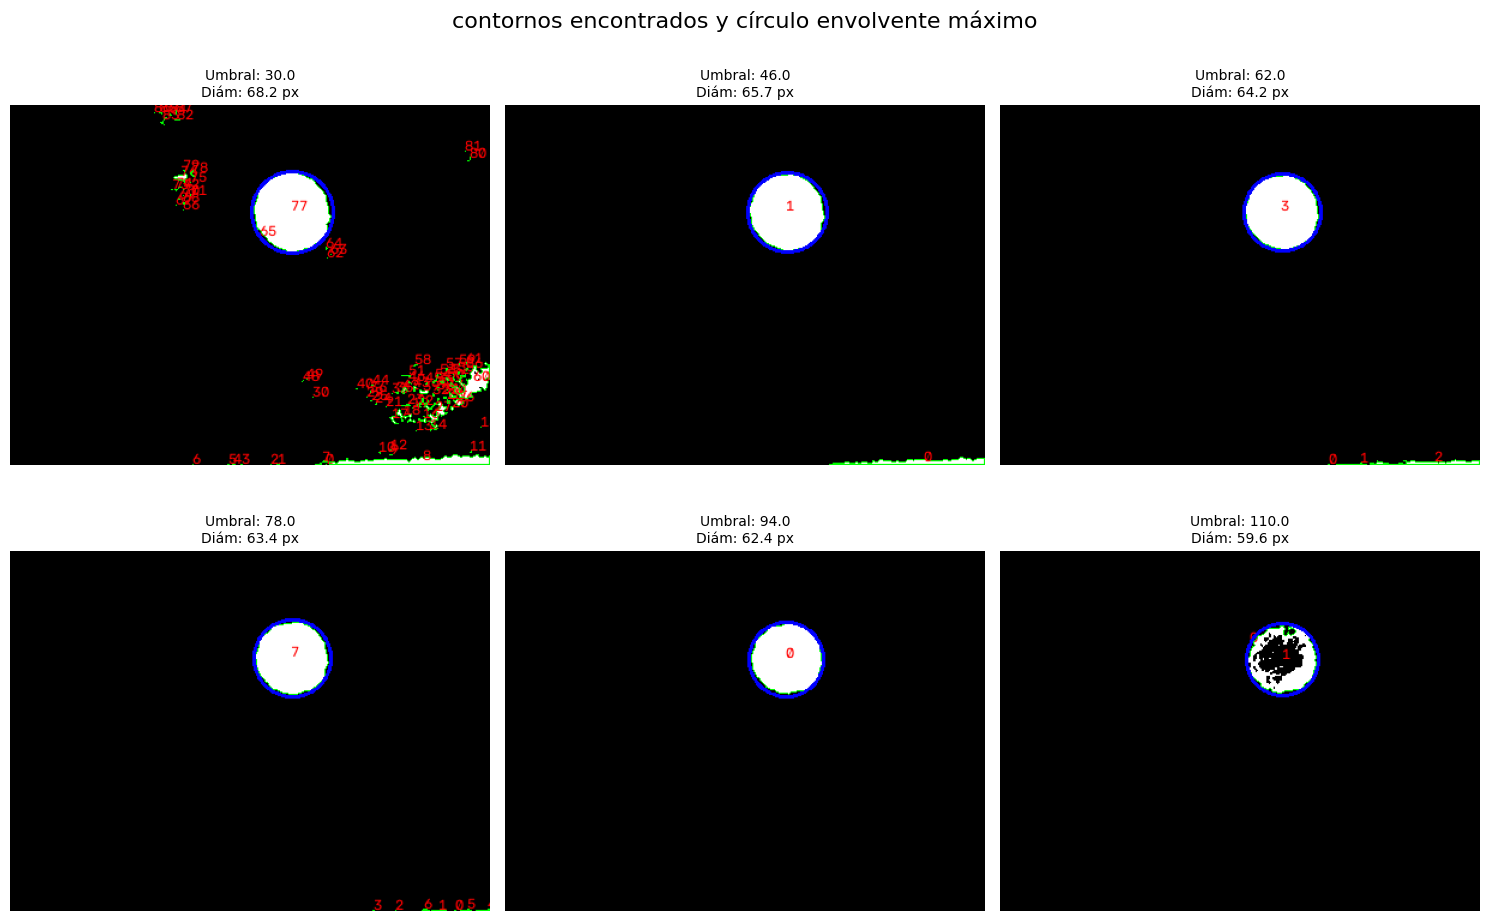

In [ ]:
# Crear una única figura con 2 filas y 3 columnas
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle("contornos encontrados y círculo envolvente máximo", fontsize=16)
axes = axes.flatten()  # Aplanar la matriz de subplots para iterar fácilmente

for i in range(6):    # Buscar los contornos en la máscara
    contornos, _ = cv2.findContours(
        mascaras[i],
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Crear una imagen en color para visualizarlos usando la máscara correspondiente a esta iteración
    visualizacion = cv2.cvtColor(mascaras[i], cv2.COLOR_GRAY2RGB)

    # Dibujar todos los contornos en verde y poner sus índices
    for j, contorno in enumerate(contornos):
        cv2.drawContours(
            visualizacion, [contorno], -1, (0, 255, 0), 1
        )

        # Calcular el centro aproximado de cada contorno usando 'contorno'
        M = cv2.moments(contorno)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            x, y, w, h = cv2.boundingRect(contorno)
            cx = x + w // 2
            cy = y + h // 2

        # Escribir el índice del contorno
        cv2.putText(visualizacion, str(j), (cx, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)

    # Si hay contornos, calcular y dibujar el círculo envolvente máximo
    if len(contornos) > 0:
        # Corregido: se especifica key=cv2.contourArea para obtener el contorno de mayor área
        contorno_maximo = max(contornos, key=cv2.contourArea)
        (cx_c, cy_c), radio = cv2.minEnclosingCircle(contorno_maximo)
        diametro = 2 * radio

        # Dibujar el círculo envolvente máximo calculado en azul sobre la misma visualización
        cv2.circle(
            visualizacion,
            (round(cx_c), round(cy_c)),
            round(radio),
            (0, 0, 255),
            2
        )
        titulo_subplot = f"Umbral: {umbral[i]:.1f}\nDiám: {diametro:.1f} px"
    else:
        titulo_subplot = f"Umbral: {umbral[i]:.1f}\nSin contornos"

    # Mostrar cada resultado en su subplot correspondiente
    axes[i].imshow(visualizacion)
    axes[i].set_title(titulo_subplot, fontsize=10)
    axes[i].axis("off")

plt.tight_layout()
plt.show()